# Phase 2 & 3: Molecular Graph and Edits

### Objective
Demonstrate how a SMILES is converted to a graph with PyTorch Geometric-compatible features, and apply edits.



In [1]:
from rdkit import Chem
from rdkit.Chem import Draw
import torch
import sys
import os
sys.path.append(os.path.abspath(".."))
from src.chemistry.molecule_editor import MoleculeEditor

### Convert RDKit Mol to Graph representation
We extract node features (element, formal charge, H count, aromaticity, ring membership) and edge features (bond type).

In [2]:
def mol_to_graph_features(mol):
    if mol is None:
        return None
    
    # Node features
    node_features = []
    for atom in mol.GetAtoms():
        feat = [
            atom.GetAtomicNum(),
            atom.GetFormalCharge(),
            atom.GetTotalNumHs(),
            int(atom.GetIsAromatic()),
            int(atom.IsInRing())
        ]
        node_features.append(feat)
        
    # Edge features
    edge_indices = []
    edge_features = []
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        bond_type = bond.GetBondTypeAsDouble()
        
        # Undirected graph (add both directions)
        edge_indices.extend([[i, j], [j, i]])
        edge_features.extend([[bond_type], [bond_type]])
        
    return {
        "x": torch.tensor(node_features, dtype=torch.float),
        "edge_index": torch.tensor(edge_indices, dtype=torch.long).t().contiguous() if edge_indices else torch.empty((2, 0), dtype=torch.long),
        "edge_attr": torch.tensor(edge_features, dtype=torch.float)
    }

Graph Dimensions:
Nodes (x): torch.Size([13, 5]) -> [num_atoms, num_node_features]
Edges (edge_index): torch.Size([2, 26]) -> [2, num_directed_edges]
Edge Attributes (edge_attr): torch.Size([26, 1]) -> [num_directed_edges, num_edge_features]


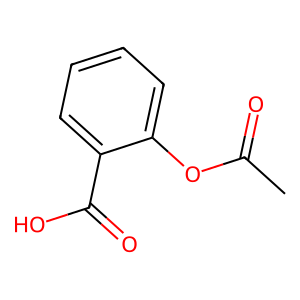

In [3]:
smiles = "CC(=O)Oc1ccccc1C(=O)O"
mol = Chem.MolFromSmiles(smiles)
graph_data = mol_to_graph_features(mol)

print("Graph Dimensions:")
print(f"Nodes (x): {graph_data['x'].shape} -> [num_atoms, num_node_features]")
print(f"Edges (edge_index): {graph_data['edge_index'].shape} -> [2, num_directed_edges]")
print(f"Edge Attributes (edge_attr): {graph_data['edge_attr'].shape} -> [num_directed_edges, num_edge_features]")

display(Draw.MolToImage(mol))

### Apply Molecular Edits
Let's test the `MoleculeEditor`.

In [4]:
editor = MoleculeEditor()
print(f"Allowed Elements for Editing: {editor.allowed_elements}")

# 1. Add Atom (Fluorine to Oxygen 3 - Invalid Action)
new_mol_1 = editor.add_atom(mol, atom_idx=3, new_element="F")
if new_mol_1:
    print("Added Fluorine:")
    display(Draw.MolToImage(new_mol_1))

Allowed Elements for Editing: ['C', 'N', 'O', 'F', 'S', 'Cl']


[21:39:11] Explicit valence for atom # 3 O, 3, is greater than permitted


Successfully Added Fluorine to Carbon 0:


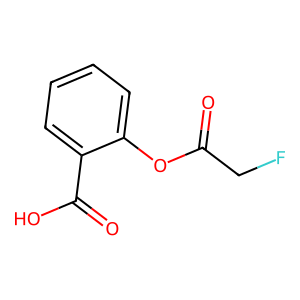

In [5]:
# 2. Add Atom (Fluorine to Carbon 0 - Valid Action)
valid_mol = editor.add_atom(mol, atom_idx=0, new_element="F")
if valid_mol:
    print("Successfully Added Fluorine to Carbon 0:")
    display(Draw.MolToImage(valid_mol))
else:
    print("Action rejected: Invalid molecule")


Successfully Removed Fluorine:


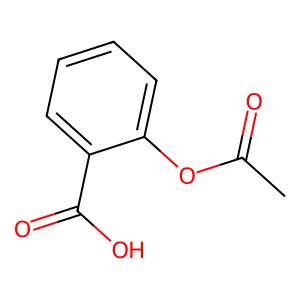

In [6]:
# 3. Remove Atom (Remove the newly added Fluorine)
if valid_mol:
    f_idx = valid_mol.GetNumAtoms() - 1
    removed_mol = editor.remove_atom(valid_mol, f_idx)
    if removed_mol:
        print("Successfully Removed Fluorine:")
        display(Draw.MolToImage(removed_mol))
